# Hourly bike-share demand: analysis walkthrough

This notebook reads the artefacts written by `python run.py all` and walks through the demand profile, the model ladder, the time-based hold-out and the error structure. It is generated by `scripts/build_notebook.py`, so the prose and the numbers cannot drift apart.

In [1]:
import json, sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 30)

## 1. Headline numbers

In [2]:
eda = json.loads((ROOT / 'reports/eda_summary.json').read_text(encoding='utf-8'))
metrics = json.loads((ROOT / 'reports/metrics.json').read_text(encoding='utf-8'))
diagnostics = json.loads(
    (ROOT / 'reports/diagnostics_summary.json').read_text(encoding='utf-8')
)
clean = json.loads((ROOT / 'reports/clean_report.json').read_text(encoding='utf-8'))
test = metrics['test']
pd.Series({
    'hours modelled': f"{eda['hours']:,}",
    'period': f"{eda['date_min'][:10]} to {eda['date_max'][:10]}",
    'total rentals': f"{eda['total_rentals']:,}",
    'missing hours on the grid': clean['missing_hours'],
    'selected model': metrics['selected_model'],
    'hold-out RMSE': test['rmse'],
    'hold-out R2': test['r2'],
    'improvement over weekly baseline': f"{metrics['improvement_vs_naive_pct']}%",
}, name='value')

hours modelled                                        16,750
period                              2011-01-08 to 2012-12-31
total rentals                                      3,234,383
missing hours on the grid                                165
selected model                             gradient_boosting
hold-out RMSE                                          43.95
hold-out R2                                           0.9531
improvement over weekly baseline                      61.83%
Name: value, dtype: object

Two cleaning decisions matter before any modelling: the 165 hours absent from the published table are reindexed onto a complete grid, and the `casual`/`registered` component columns are dropped because they sum to the target and would leak it.

## 2. The shape of demand

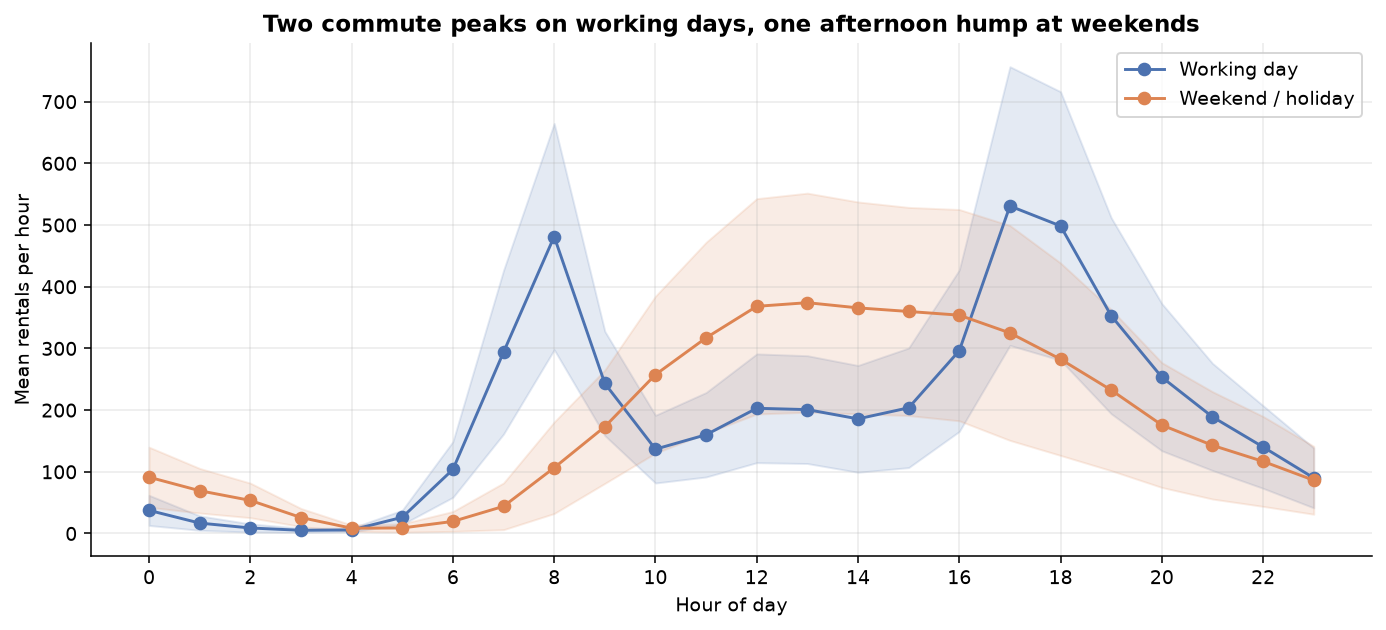

In [3]:
display(Image(filename=str(ROOT / 'reports/figures/02_hourly_profile.png')))

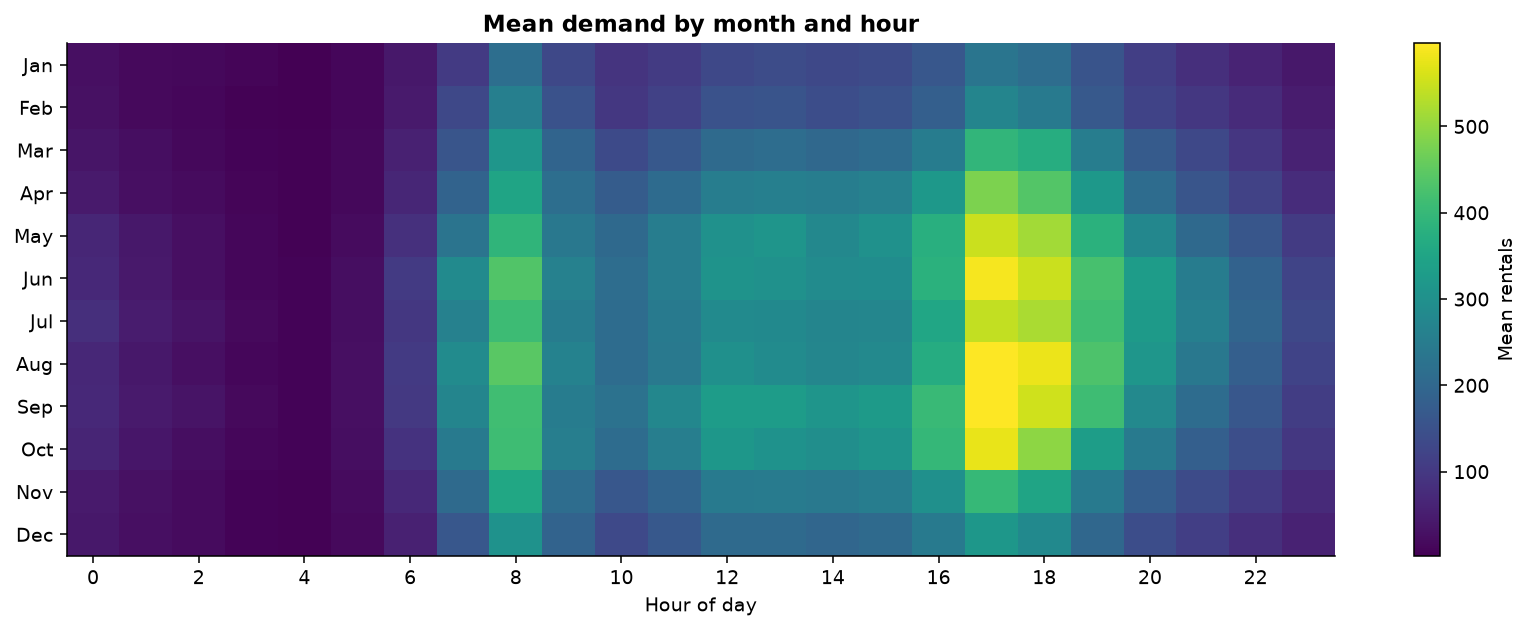

In [4]:
display(Image(filename=str(ROOT / 'reports/figures/03_month_hour_heatmap.png')))

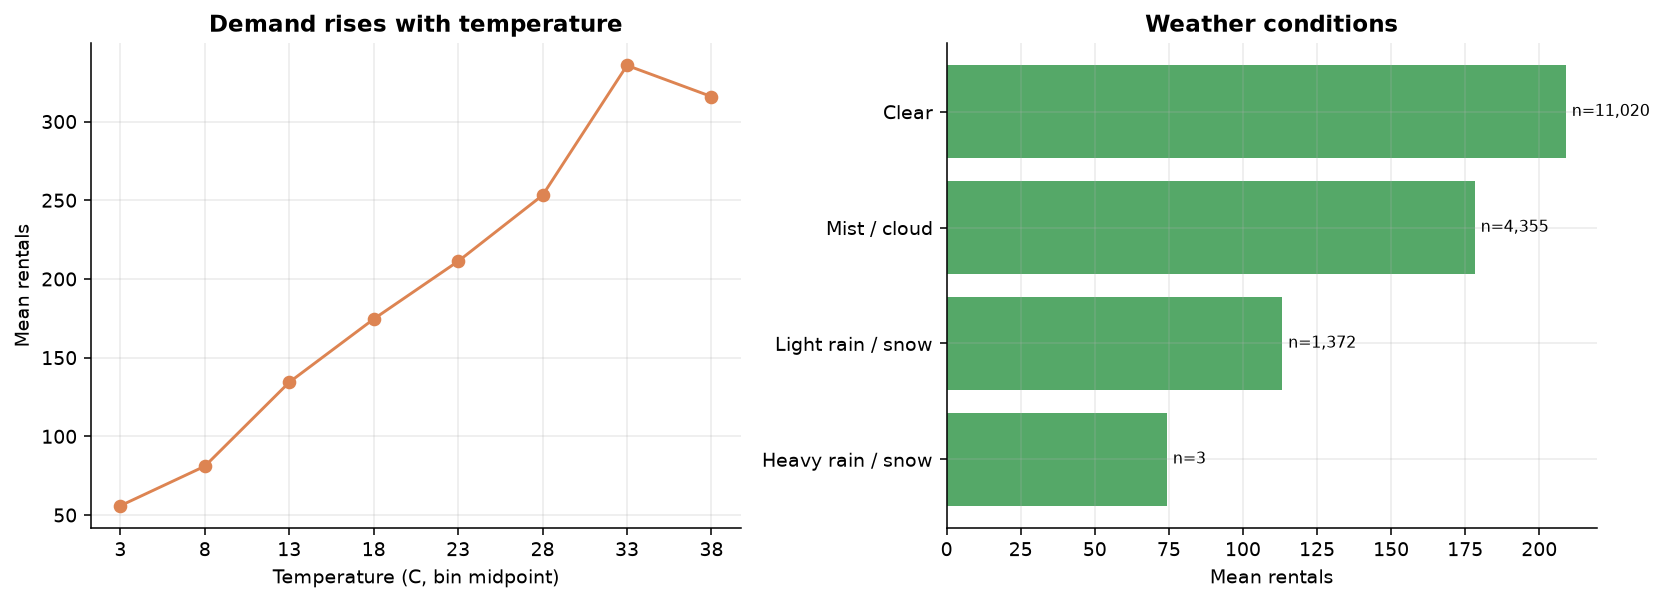

In [5]:
display(Image(filename=str(ROOT / 'reports/figures/04_weather_effects.png')))

Demand has two commute peaks around 08:00 and 17:00, a summer maximum and a clear weather gradient. Any model that ignores the calendar starts from a handicap; the seasonal-naive baseline captures exactly that structure.

## 3. Model ladder

In [6]:
cv = pd.DataFrame(metrics['cv']).T[['rmse_mean', 'rmse_std', 'mae_mean']]
test_all = pd.DataFrame(metrics['test_all_models']).T[['rmse', 'mae', 'r2', 'mape']]
display(cv.round(2))
test_all.round(3)

,rmse_mean,rmse_std,mae_mean
ridge_regression,81.98,12.98,53.32
gradient_boosting,52.85,13.22,32.20


,rmse,mae,r2,mape
seasonal_naive,115.143,68.948,0.678,82.12
ridge_regression,72.971,46.401,0.871,33.13
gradient_boosting,43.950,27.420,0.953,21.47


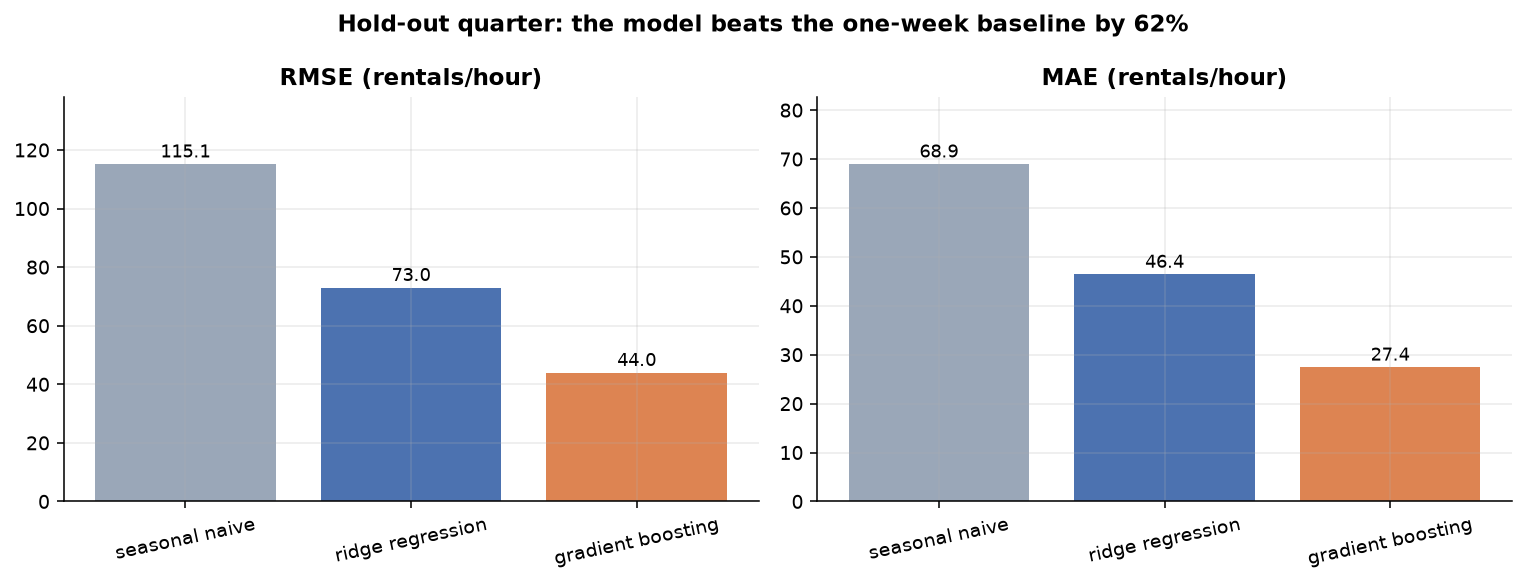

In [7]:
display(Image(filename=str(ROOT / 'reports/figures/09_model_comparison.png')))

Model selection uses expanding-window validation on the training period only. The hold-out quarter from 2012-10-01 is scored once, after selection.

## 4. One hold-out week

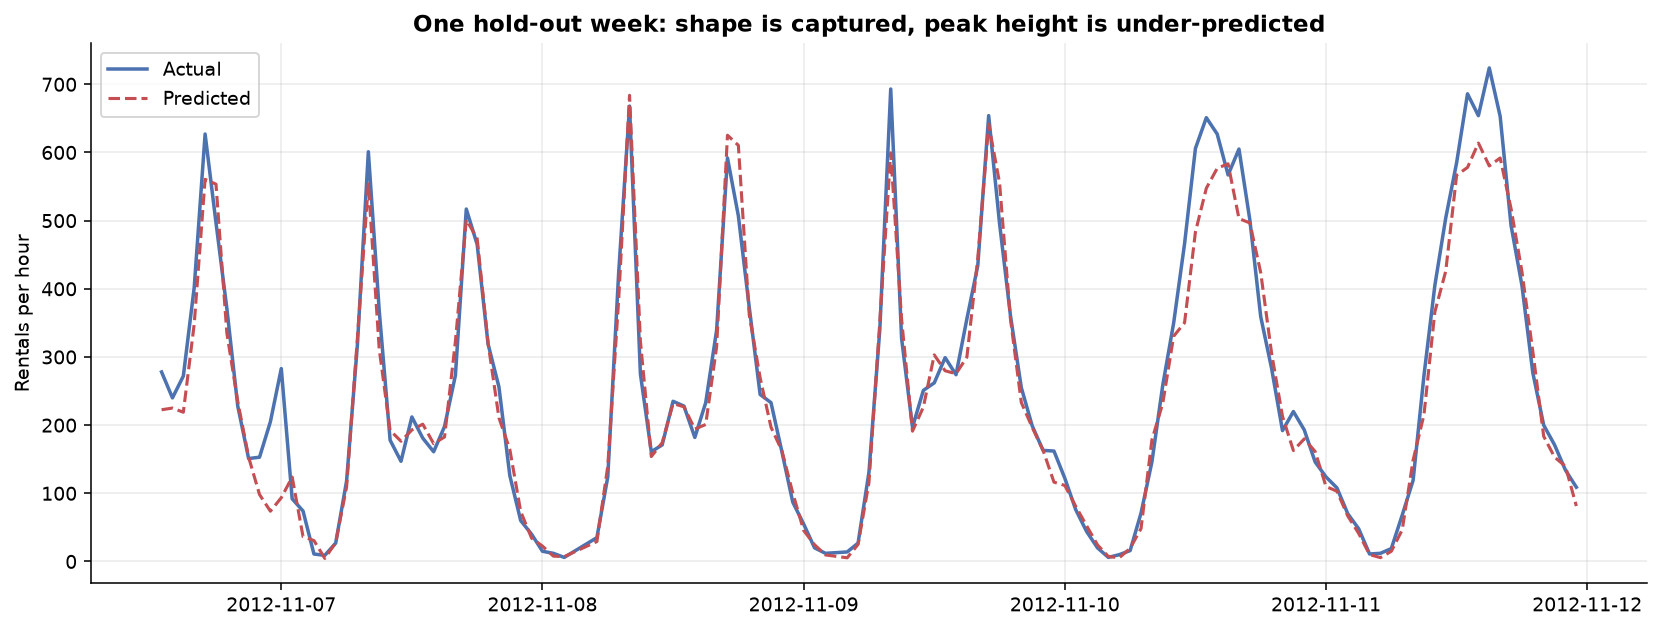

In [8]:
display(Image(filename=str(ROOT / 'reports/figures/15_forecast_week.png')))

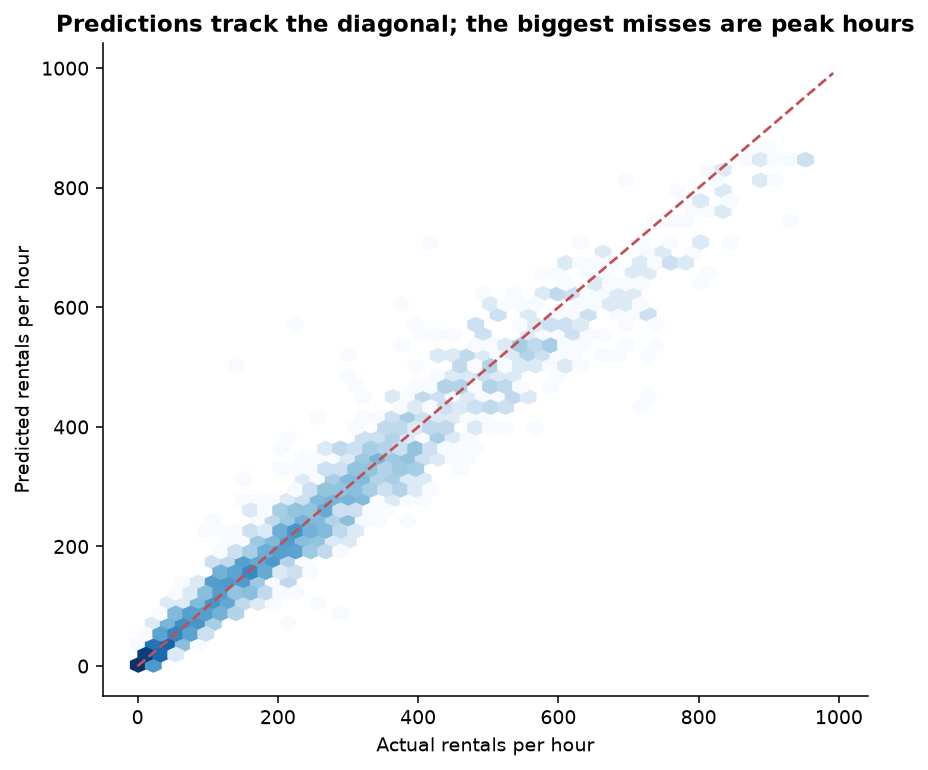

In [9]:
display(Image(filename=str(ROOT / 'reports/figures/10_predicted_vs_actual.png')))

The model tracks the daily shape closely and flattens the tallest evening peaks: fitting on the log scale trades a little peak height for stability across the rest of the day.

## 5. Where the errors concentrate

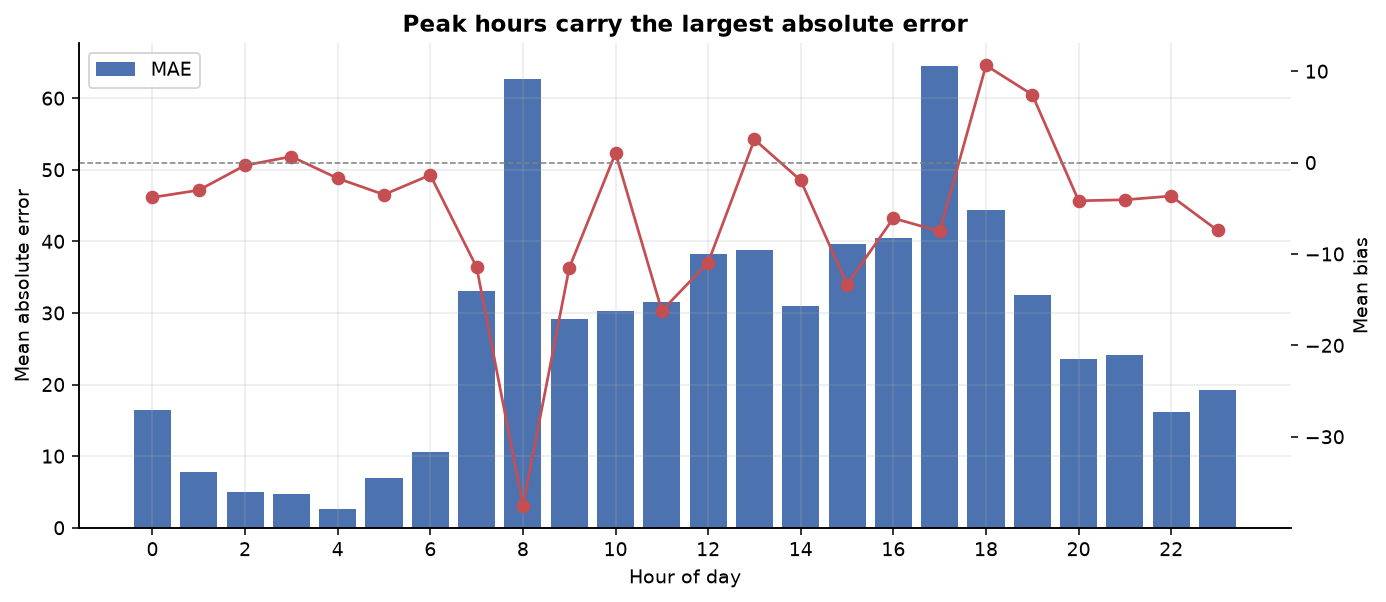

In [10]:
display(Image(filename=str(ROOT / 'reports/figures/12_error_by_hour.png')))

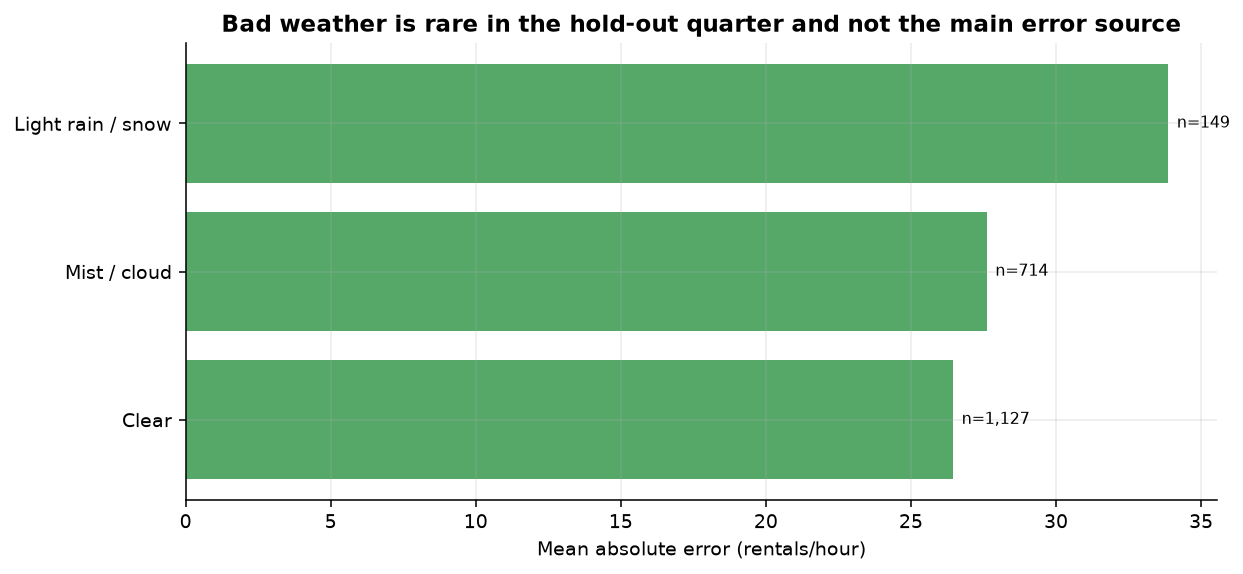

In [11]:
display(Image(filename=str(ROOT / 'reports/figures/13_error_by_weather.png')))

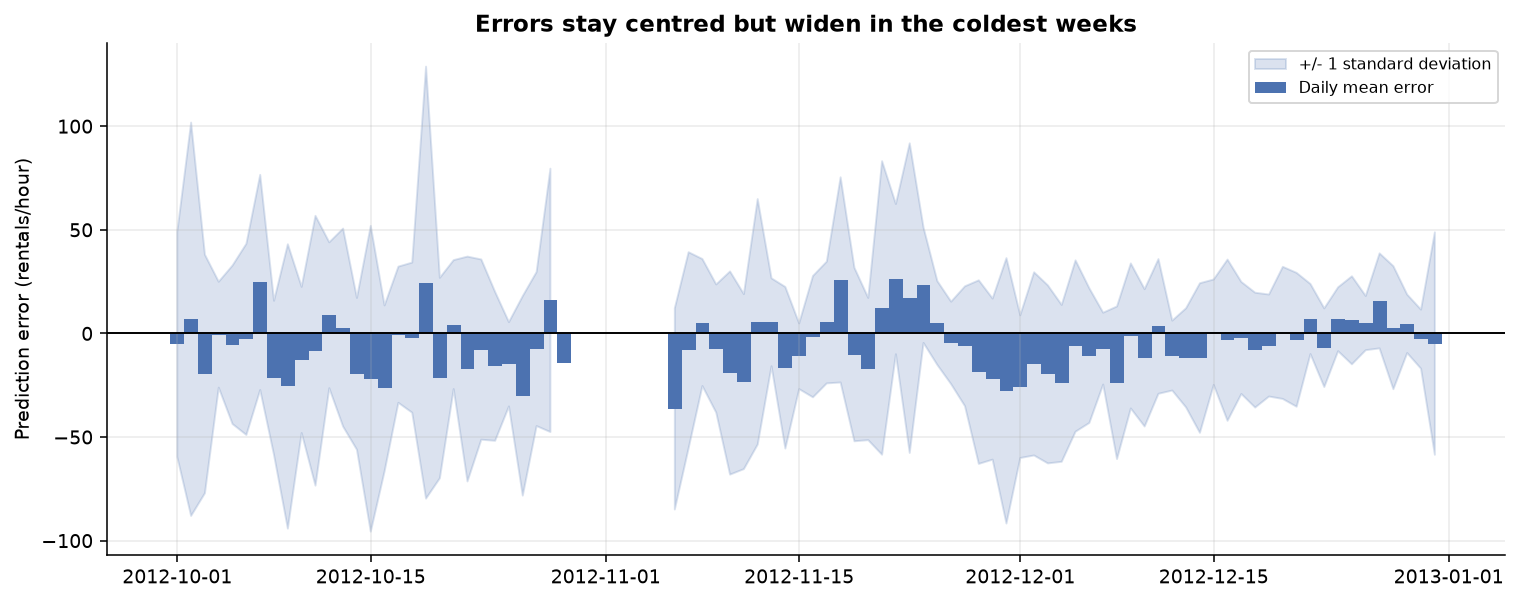

In [12]:
display(Image(filename=str(ROOT / 'reports/figures/11_residuals_over_time.png')))

In [13]:
pd.Series({
    'worst hour': f"{diagnostics['worst_hour']['hour']:02d}:00",
    'MAE at worst hour': diagnostics['worst_hour']['mae'],
    'best hour': f"{diagnostics['best_hour']['hour']:02d}:00",
    'MAE at best hour': diagnostics['best_hour']['mae'],
    'share within 25% of actual': f"{diagnostics['share_within_25pct']:.1%}",
    'daily bias range': diagnostics['daily_bias_range'],
}, name='value')

worst hour                              17:00
MAE at worst hour                       64.43
best hour                               04:00
MAE at best hour                         2.67
share within 25% of actual              75.7%
daily bias range              [-36.42, 26.21]
Name: value, dtype: object

Absolute error is concentrated in the evening peak, which is also where the operational decisions are made. Reporting a single RMSE hides that; the percentage-within-band figure is the fairer summary for capacity planning.

## 6. What drives the forecast

In [14]:
pd.DataFrame(metrics['feature_importance']).head(10).round(4)

,feature,importance_mean,importance_std
0,demand_lag_1h,0.8721,0.0317
1,demand_lag_168h,0.0488,0.0035
2,hour_cos,0.0357,0.0026
3,hr,0.0251,0.0014
4,workingday,0.0248,0.0021
5,hour_sin,0.0188,0.0017
6,demand_lag_24h,0.0182,0.0010
7,hour_sin2,0.0171,0.0013
8,hour_cos2,0.0152,0.0018
9,temp,0.0108,0.0004


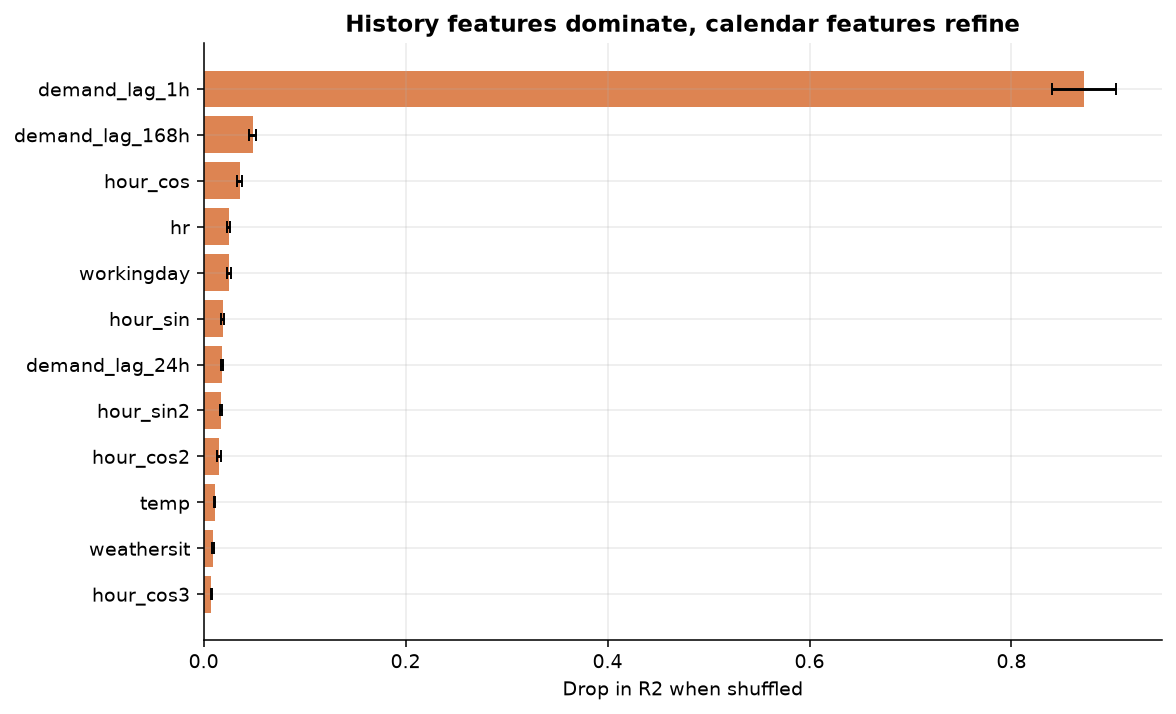

In [15]:
display(Image(filename=str(ROOT / 'reports/figures/14_feature_importance.png')))

Permutation importance on the hold-out quarter puts recent demand first, with the weekly lag and hour encodings filling in the shape.

## 7. Reproducing the results

`reports/REPORT.md` carries the full narrative and `reports/model_card.md` the intended-use statement. Rebuild everything with:

```bash
python run.py all
```